# Part 2, Rohan: decision trees, random forest and gradient boosting

**Models (lecture 4):** a single regression tree, a random forest (bagged deep trees, lowers variance) and histogram gradient boosting (shallow trees added one after another, lowers bias).

**Features:** Sanath's `cache/features_C.py` (final 6 groups, 25 features, already tested for leakage and parity), so the only difference from his linear model is the model itself. The inputs are log-transformed, which does not matter for trees: a split only depends on the order of values.

**Protocol:** fit on training rows (targets 3 Jan – 31 Aug, 113,256 rows), choose everything on validation (targets 1 Sep – 30 Nov, 42,588 rows), score in µg/m³ with `B.evaluate`. Gradient boosting uses `early_stopping=False` because its built-in early stopping holds out a *random* 10% of rows, which mixes days across time.

In [1]:
import os, sys, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

SEED = 0
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd()
if not (ROOT / "baseline.py").exists():
    ROOT = ROOT.parent                      # notebook lives in models/
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import baseline as B
from cache import features_C as FC
B.self_check()

baseline.py OK


,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
Persistence,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70
Ridge (Part 1),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81


## 1. Data, targets and features

In [2]:
W, stations = B.load_data()
T_train, T_val = B.issue_times()
y_train, y_val = B.targets(W, T_train), B.targets(W, T_val)
p_train, p_val = B.persistence(W, T_train), B.persistence(W, T_val)   # reading at the issue time

ctx = FC.build_ctx(W, stations)                                  # fitted on training hours only
X_train, names, groups = FC.extract_features(W, T_train, ctx)    # FINAL_GROUPS
X_val, _, _ = FC.extract_features(W, T_val, ctx)
ALL = list(range(X_train.shape[1]))
print(X_train.shape, X_val.shape)

# How many distinct values does each group take on the training rows?
pd.DataFrame({g: {"n_features": len(c), "distinct values (first column)": len(np.unique(X_train[:, c[0]]))}
              for g, c in groups.items()}).T

(113256, 25) (42588, 25)


,n_features,distinct values (first column)
own,12,13543
prevday,1,13607
nbr,5,66216
network,3,242
trend,3,88546
long,1,111906


Note the `network` group: 242 distinct values, one per training day, because it is the same number for all 468 stations on a given day. Keep this in mind for section 4.

In [3]:
def back(z, target, persist):
    """Convert a prediction in target space back to µg/m³."""
    if target == "level":  return z
    if target == "change": return persist + z
    if target == "log":    return np.expm1(z)
    raise ValueError(target)

def target_values(target):
    return {"level": y_train, "change": y_train - p_train, "log": np.log1p(y_train)}[target]

def rmse(pred, y):
    return float(np.sqrt(np.mean((np.clip(pred, 0, None) - y) ** 2)))

def score(name, pred_tr, pred_va):
    va = B.evaluate(pred_va, y_val, T_val)
    return {"model": name, "train RMSE": rmse(pred_tr, y_train) if pred_tr is not None else np.nan,
            "val RMSE": va["RMSE"], "val MAE": va["MAE"],
            "Sep": va["RMSE Sep"], "Oct": va["RMSE Oct"], "Nov": va["RMSE Nov"],
            "bias": float(np.mean(np.clip(pred_va, 0, None) - y_val))}

def load_preds(name):
    """Teammates' saved validation forecasts (91 days x 468 stations) -> flat array."""
    return pd.read_parquet(f"preds/{name}.parquet").to_numpy().ravel()

reference = [
    score("Persistence", p_train, p_val),
    score("Ridge (Part 1)", None, B.part1_ridge_predict(W, stations, T_val)),
    score("B: ridge final (Ponish)", None, load_preds("B_ridge_final_level")),
    score("C: Laplace smeared mean (Sanath)", None, load_preds("sanath_laplace_mean")),
    score("D: kNN (Saanvi)", None, load_preds("saanvi_knn")),
]
pd.DataFrame(reference).set_index("model").round(2)

,train RMSE,val RMSE,val MAE,Sep,Oct,Nov,bias
model,,,,,,,
Persistence,32.91,32.75,17.47,23.33,20.22,47.81,-0.47
Ridge (Part 1),NaN,29.58,18.16,20.34,19.36,43.06,5.32
B: ridge final (Ponish),NaN,28.71,16.43,19.51,18.16,42.17,-0.48
C: Laplace smeared mean (Sanath),NaN,28.16,15.74,20.05,17.57,41.05,-0.30
D: kNN (Saanvi),NaN,29.12,16.38,19.75,18.17,42.91,-0.56


## 2. A single decision tree: depth sweep
Target = change from persistence (tomorrow's reading minus today's). Deeper trees fit training better; watch what happens on validation.

,max_depth,leaves,train RMSE,val RMSE
0,2,4,30.29,32.35
1,3,8,29.54,31.13
2,4,16,28.59,32.71
3,5,32,27.71,34.40
4,6,63,26.99,36.82
5,8,218,25.23,38.79
6,10,648,23.25,39.40
7,12,1670,20.90,41.07
8,15,5061,17.09,43.90
9,20,17731,11.38,46.48


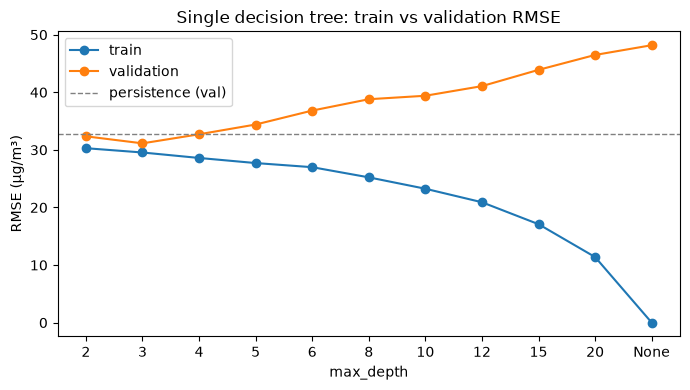

{'model': 'Decision tree (depth 3, change)',
 'train RMSE': 29.543210289362626,
 'val RMSE': np.float64(31.13231502640733),
 'val MAE': np.float64(17.16752273659391),
 'Sep': np.float64(21.480100506576626),
 'Oct': np.float64(18.95216385513652),
 'Nov': np.float64(45.90662735324328),
 'bias': -1.1325905715287152}

In [4]:
depths = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
rows = []
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(X_train, y_train - p_train)
    rows.append({"max_depth": "None" if d is None else d,
                 "leaves": tree.get_n_leaves(),
                 "train RMSE": rmse(p_train + tree.predict(X_train), y_train),
                 "val RMSE": rmse(p_val + tree.predict(X_val), y_val)})
dt_sweep = pd.DataFrame(rows)
display(dt_sweep.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(dt_sweep))
ax.plot(x, dt_sweep["train RMSE"], marker="o", label="train")
ax.plot(x, dt_sweep["val RMSE"], marker="o", label="validation")
ax.axhline(32.75, color="grey", ls="--", lw=1, label="persistence (val)")
ax.set_xticks(list(x)); ax.set_xticklabels(dt_sweep["max_depth"])
ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE (µg/m³)")
ax.set_title("Single decision tree: train vs validation RMSE")
ax.legend(); fig.tight_layout(); plt.show()

best_d = dt_sweep.loc[dt_sweep["val RMSE"].idxmin(), "max_depth"]
best_d = None if best_d == "None" else int(best_d)
tree = DecisionTreeRegressor(max_depth=best_d, random_state=SEED).fit(X_train, y_train - p_train)
tree_row = score(f"Decision tree (depth {best_d}, change)", p_train + tree.predict(X_train), p_val + tree.predict(X_val))
tree_row

## 3. Gradient boosting: which target?
Same model, three targets. `staged_predict` gives the forecast after every boosting iteration, so one fit shows the whole train/validation curve.

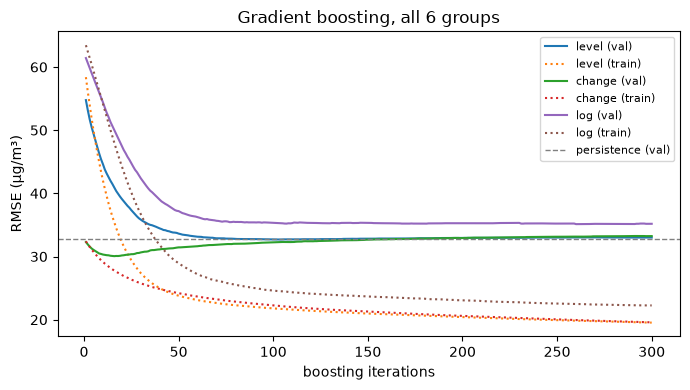

,best iter,train at best,val at best,val at 300
level,104.0,21.72,32.69,33.01
change,16.0,27.77,30.06,33.24
log,263.0,22.48,35.13,35.18


In [5]:
def hgb_curve(cols, target, **params):
    """Fit HGB and return (model, DataFrame of train/val RMSE after each iteration)."""
    model = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **params)
    model.fit(X_train[:, cols], target_values(target))
    rows = []
    for i, (zt, zv) in enumerate(zip(model.staged_predict(X_train[:, cols]),
                                     model.staged_predict(X_val[:, cols])), start=1):
        rows.append({"iter": i, "train": rmse(back(zt, target, p_train), y_train),
                     "val": rmse(back(zv, target, p_val), y_val)})
    return model, pd.DataFrame(rows)

BASE = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50)
curves = {}
fig, ax = plt.subplots(figsize=(7, 4))
for target in ["level", "change", "log"]:
    _, curves[target] = hgb_curve(ALL, target, **BASE)
    c = curves[target]
    ax.plot(c["iter"], c["val"], label=f"{target} (val)")
    ax.plot(c["iter"], c["train"], ls=":", label=f"{target} (train)")
ax.axhline(32.75, color="grey", ls="--", lw=1, label="persistence (val)")
ax.set_xlabel("boosting iterations"); ax.set_ylabel("RMSE (µg/m³)")
ax.set_title("Gradient boosting, all 6 groups"); ax.legend(fontsize=8); fig.tight_layout(); plt.show()

pd.DataFrame({t: {"best iter": int(c.loc[c.val.idxmin(), "iter"]), "train at best": c.loc[c.val.idxmin(), "train"],
                  "val at best": c.val.min(), "val at 300": c.val.iloc[-1]}
              for t, c in curves.items()}).T.round(2)

## 4. Diagnosis: why do the trees overfit?
The `network` features take only 242 distinct values in training (one per day). A tree can split on them to isolate individual training days and learn what happened next on exactly those days, which does not carry over to new days. Test: refit without the `network` group.

In [6]:
NO_NET = [c for g, cols in groups.items() if g != "network" for c in cols]
diag = []
for label, cols in [("all 6 groups", ALL), ("without network", NO_NET)]:
    for target in ["level", "change"]:
        _, c = hgb_curve(cols, target, **BASE)
        best = c.loc[c.val.idxmin()]
        diag.append({"features": label, "target": target, "best iter": int(best["iter"]),
                     "train at best": best["train"], "val at best": best["val"], "val at 300": c.val.iloc[-1]})
pd.DataFrame(diag).round(2)

,features,target,best iter,train at best,val at best,val at 300
0,all 6 groups,level,104,21.72,32.69,33.01
1,all 6 groups,change,16,27.77,30.06,33.24
2,without network,level,79,25.42,29.72,30.10
3,without network,change,43,27.20,29.08,29.92


## 5. Tuning gradient boosting (without `network`, change target)
Small grid; the number of iterations is chosen on validation from the staged curve. `min_samples_leaf` is the main brake on memorising days (a leaf must contain many rows).

In [7]:
grid = []
for leaves in [15, 31]:
    for msl in [50, 500, 2000]:
        for loss in ["squared_error", "absolute_error"]:
            params = dict(max_iter=400, learning_rate=0.05, max_leaf_nodes=leaves, min_samples_leaf=msl, loss=loss)
            _, c = hgb_curve(NO_NET, "change", **params)
            best = c.loc[c.val.idxmin()]
            grid.append({"max_leaf_nodes": leaves, "min_samples_leaf": msl, "loss": loss,
                         "best iter": int(best["iter"]), "train at best": best["train"], "val at best": best["val"]})
hgb_grid = pd.DataFrame(grid).sort_values("val at best")
display(hgb_grid.round(2))

top = hgb_grid.iloc[0]
HGB_PARAMS = dict(max_iter=int(top["best iter"]), learning_rate=0.05, max_leaf_nodes=int(top["max_leaf_nodes"]),
                  min_samples_leaf=int(top["min_samples_leaf"]), loss=top["loss"])
hgb = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **HGB_PARAMS).fit(X_train[:, NO_NET], y_train - p_train)
hgb_tr, hgb_va = p_train + hgb.predict(X_train[:, NO_NET]), p_val + hgb.predict(X_val[:, NO_NET])
hgb_row = score("Gradient boosting (no network, change)", hgb_tr, hgb_va)
print(HGB_PARAMS); hgb_row

,max_leaf_nodes,min_samples_leaf,loss,best iter,train at best,val at best
0,15,50,squared_error,64,27.44,29.05
6,31,50,squared_error,43,27.20,29.08
2,15,500,squared_error,74,27.68,29.16
8,31,500,squared_error,46,27.68,29.32
1,15,50,absolute_error,119,28.34,29.54
4,15,2000,squared_error,106,28.18,29.57
10,31,2000,squared_error,148,27.71,29.67
7,31,50,absolute_error,75,28.29,29.72
3,15,500,absolute_error,83,28.94,29.73
9,31,500,absolute_error,73,28.61,29.83


{'max_iter': 64, 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50, 'loss': 'squared_error'}


{'model': 'Gradient boosting (no network, change)',
 'train RMSE': 27.44062605157623,
 'val RMSE': np.float64(29.047909855523812),
 'val MAE': np.float64(16.27671574033882),
 'Sep': np.float64(19.820733028859042),
 'Oct': np.float64(17.966224996964186),
 'Nov': np.float64(42.8142853499332),
 'bias': -1.5588036382314452}

## 6. Random forest (without `network`, change target)
Each tree sees a bootstrap half of the rows (`max_samples=0.5`) and a random subset of features at each split (`max_features`); averaging 200 such trees lowers variance. This takes a few minutes.

In [8]:
rf_rows = []
for msl in [20, 100, 500]:
    for mf in [0.33, 0.66]:
        t0 = time.time()
        rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=msl, max_features=mf, max_samples=0.5,
                                   n_jobs=-1, random_state=SEED).fit(X_train[:, NO_NET], y_train - p_train)
        rf_rows.append({"min_samples_leaf": msl, "max_features": mf,
                        "train RMSE": rmse(p_train + rf.predict(X_train[:, NO_NET]), y_train),
                        "val RMSE": rmse(p_val + rf.predict(X_val[:, NO_NET]), y_val),
                        "seconds": round(time.time() - t0)})
rf_grid = pd.DataFrame(rf_rows).sort_values("val RMSE")
display(rf_grid.round(2))

top = rf_grid.iloc[0]
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=int(top["min_samples_leaf"]), max_features=float(top["max_features"]),
                 max_samples=0.5, n_jobs=-1, random_state=SEED)
rf = RandomForestRegressor(**RF_PARAMS).fit(X_train[:, NO_NET], y_train - p_train)
rf_tr, rf_va = p_train + rf.predict(X_train[:, NO_NET]), p_val + rf.predict(X_val[:, NO_NET])
rf_row = score("Random forest (no network, change)", rf_tr, rf_va)
print(RF_PARAMS); rf_row

,min_samples_leaf,max_features,train RMSE,val RMSE,seconds
3,100,0.66,27.30,29.24,17
0,20,0.33,24.89,29.28,12
2,100,0.33,27.66,29.30,11
1,20,0.66,24.41,29.49,22
5,500,0.66,29.18,29.75,13
4,500,0.33,29.46,29.92,7


{'n_estimators': 200, 'min_samples_leaf': 100, 'max_features': 0.66, 'max_samples': 0.5, 'n_jobs': -1, 'random_state': 0}


{'model': 'Random forest (no network, change)',
 'train RMSE': 27.302471366390236,
 'val RMSE': np.float64(29.237918862709257),
 'val MAE': np.float64(16.503343592299164),
 'Sep': np.float64(19.631811252527843),
 'Oct': np.float64(18.61197958820387),
 'Nov': np.float64(43.00816478524593),
 'bias': -2.2228785224559817}

## 7. Comparison with the baselines and teammates' models

In [9]:
summary = pd.DataFrame(reference + [tree_row, rf_row, hgb_row]).set_index("model")
summary["val - train gap"] = summary["val RMSE"] - summary["train RMSE"]
display(summary.round(2))

# Block bootstrap over validation DAYS (days are correlated, so resample whole days)
def day_rmse_sq(pred):
    e2 = (np.clip(pred, 0, None) - y_val) ** 2
    return e2.reshape(len(T_val), -1).mean(axis=1)

def bootstrap_gap(pred_a, pred_b, n=2000, block=7):
    rng = np.random.default_rng(SEED)
    da, db = day_rmse_sq(pred_a), day_rmse_sq(pred_b)
    nd, out = len(da), []
    for _ in range(n):
        starts = rng.integers(0, nd - block + 1, size=nd // block + 1)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:nd]
        out.append(np.sqrt(da[idx].mean()) - np.sqrt(db[idx].mean()))
    return np.percentile(out, [2.5, 50, 97.5]).round(2)

best_tree_pred = hgb_va if hgb_row["val RMSE"] <= rf_row["val RMSE"] else rf_va
print("best tree minus Part 1 ridge   :", bootstrap_gap(best_tree_pred, B.part1_ridge_predict(W, stations, T_val)))
print("best tree minus C (Sanath)     :", bootstrap_gap(best_tree_pred, load_preds("sanath_laplace_mean")))

,train RMSE,val RMSE,val MAE,Sep,Oct,Nov,bias,val - train gap
model,,,,,,,,
Persistence,32.91,32.75,17.47,23.33,20.22,47.81,-0.47,-0.16
Ridge (Part 1),NaN,29.58,18.16,20.34,19.36,43.06,5.32,NaN
B: ridge final (Ponish),NaN,28.71,16.43,19.51,18.16,42.17,-0.48,NaN
C: Laplace smeared mean (Sanath),NaN,28.16,15.74,20.05,17.57,41.05,-0.30,NaN
D: kNN (Saanvi),NaN,29.12,16.38,19.75,18.17,42.91,-0.56,NaN
"Decision tree (depth 3, change)",29.54,31.13,17.17,21.48,18.95,45.91,-1.13,1.59
"Random forest (no network, change)",27.30,29.24,16.50,19.63,18.61,43.01,-2.22,1.94
"Gradient boosting (no network, change)",27.44,29.05,16.28,19.82,17.97,42.81,-1.56,1.61


best tree minus Part 1 ridge   : [-1.15 -0.22  0.53]
best tree minus C (Sanath)     : [0.08 0.66 1.31]


## 8. Ablation on the best tree model
Same hyper-parameters; drop one feature group at a time (the `network` row shows what adding it back does).

In [10]:
use_hgb = hgb_row["val RMSE"] <= rf_row["val RMSE"]
def fit_predict(cols):
    if use_hgb:
        m = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **HGB_PARAMS)
    else:
        m = RandomForestRegressor(**RF_PARAMS)
    m.fit(X_train[:, cols], y_train - p_train)
    return p_val + m.predict(X_val[:, cols])

base_val = (hgb_row if use_hgb else rf_row)["val RMSE"]
abl = [{"setting": "final (no network)", "n_features": len(NO_NET), "val RMSE": base_val, "delta": 0.0}]
for g, cols in groups.items():
    if g == "network":
        use = sorted(NO_NET + cols); label = "+ network"
    else:
        use = [c for c in NO_NET if c not in cols]; label = f"- {g}"
    v = rmse(fit_predict(use), y_val)
    abl.append({"setting": label, "n_features": len(use), "val RMSE": v, "delta": v - base_val})
print("model:", "gradient boosting" if use_hgb else "random forest")
pd.DataFrame(abl).round(2)

model: gradient boosting


,setting,n_features,val RMSE,delta
0,final (no network),22,29.05,0.00
1,- own,10,29.35,0.31
2,- prevday,21,29.04,-0.00
3,- nbr,17,29.26,0.21
4,+ network,25,31.17,2.12
5,- trend,19,29.17,0.12
6,- long,21,29.08,0.04


## 9. Save validation predictions and results log

In [11]:
Path("preds").mkdir(exist_ok=True)
target_index = pd.DatetimeIndex(T_val) + pd.Timedelta(hours=24)
for name, pred in [("rohan_hgb", hgb_va), ("rohan_rf", rf_va)]:
    pd.DataFrame(np.clip(pred, 0, None).reshape(len(T_val), -1), index=target_index,
                 columns=W.columns).to_parquet(f"preds/{name}.parquet")

log = pd.DataFrame([
    {"Member": "A", "Model": "Decision tree", "Features": "C final 6 groups", "Target": "change",
     "Hyperparameters": f"max_depth={best_d}", **{k: tree_row[k] for k in ["train RMSE", "val RMSE", "val MAE", "Sep", "Oct", "Nov"]}},
    {"Member": "A", "Model": "Random forest", "Features": "C groups minus network", "Target": "change",
     "Hyperparameters": str({k: v for k, v in RF_PARAMS.items() if k not in ("n_jobs", "random_state")}),
     **{k: rf_row[k] for k in ["train RMSE", "val RMSE", "val MAE", "Sep", "Oct", "Nov"]}},
    {"Member": "A", "Model": "HistGradientBoosting", "Features": "C groups minus network", "Target": "change",
     "Hyperparameters": str(HGB_PARAMS), **{k: hgb_row[k] for k in ["train RMSE", "val RMSE", "val MAE", "Sep", "Oct", "Nov"]}},
]).round(2)
log.to_csv("results_log_A.csv", index=False)
log

,Member,Model,Features,Target,Hyperparameters,train RMSE,val RMSE,val MAE,Sep,Oct,Nov
0,A,Decision tree,C final 6 groups,change,max_depth=3,29.54,31.13,17.17,21.48,18.95,45.91
1,A,Random forest,C groups minus network,change,"{'n_estimators': 200, 'min_samples_leaf': 100,...",27.30,29.24,16.50,19.63,18.61,43.01
2,A,HistGradientBoosting,C groups minus network,change,"{'max_iter': 64, 'learning_rate': 0.05, 'max_l...",27.44,29.05,16.28,19.82,17.97,42.81


## 10. Interpretation

**Single tree: overfitting in its plainest form (section 2).** As depth grows, training RMSE falls steadily (30.29 at depth 2, 0.00 with no depth limit) while validation RMSE is best at depth 3 (31.13) and then climbs to 48.18. A deep tree ends up with almost one leaf per training row (108,657 leaves), so it memorises the training days instead of learning rules that carry over. Even the best single tree loses to Part 1 ridge (31.13 vs 29.58): one tree is too coarse at shallow depth and too noisy at large depth.

**Target (section 3).** Change from persistence works best for trees: the model only has to learn how tomorrow differs from today, and anything it cannot explain falls back to persistence. The level target is worse (best 32.69) and the log target is clearly worst (35.13), because a tree trained on log values predicts an average in log space, which back-transforms to something close to the median and under-predicts the mean that RMSE rewards.

**Why the trees overfit: day-level features (section 4).** The `network` group is the same number for all 468 stations on a given day, so in training it takes only 242 distinct values. A tree can split on it to isolate individual training days and learn what happened next on exactly those days. That does not transfer to new days. Removing `network` lowers validation RMSE from 30.06 to 29.08 (change target), and in the ablation adding it back costs +2.12 RMSE. For the linear models the same group was the most useful one (Sanath: +0.82 when removed): a linear model can only use it as one smooth slope, so it cannot memorise days with it. The same information helps a low-variance model and hurts a high-variance one.

**Tuned ensembles (sections 5 and 6).** Gradient boosting (shallow trees with 15 leaves, at least 50 rows per leaf, 64 iterations) reaches validation RMSE 29.05 and MAE 16.28; the random forest (200 trees, at least 100 rows per leaf) reaches 29.24 and 16.50. In both, validation is best with few iterations or large leaves, and more capacity only lowers training error. Absolute loss did not help boosting (every absolute-loss setting scored worse than its squared-loss twin), unlike for Sanath's linear model; trees already limit the influence of outliers by averaging within leaves.

**Did a more flexible model beat ridge? (spec question 2).** Partly. The ensembles beat persistence clearly and Part 1 ridge on MAE (16.28 vs 18.16), but on RMSE the gap to Part 1 ridge is within noise (block-bootstrap 95% interval for gradient boosting minus ridge: [-1.15, +0.53]). They lose to the improved linear models: Sanath's Laplace model is better by 0.66 RMSE (interval [+0.08, +1.31]). Every tree model fits the training months better than it fits validation (gap +1.6 to +1.9 RMSE, against about 0.15 for Sanath's model). Two reasons: (1) trees have far more capacity than a linear model and use it to fit day-specific patterns, which a training set of only 242 distinct days cannot pin down; (2) trees predict averages of training leaves, so they cannot extrapolate a trend, while a linear model in log space scales its forecast with the current level, which suits the rising Sep to Nov season.

**Ablation of the best tree (section 8).** `own` (+0.31) and `nbr` (+0.21) matter most, then `trend` (+0.12); `long` (+0.04) and `prevday` (0.00) add nothing because their information is already in the other groups. As for the linear models, region-wide and neighbourhood information carries most of the signal, but for trees it only helps as station-level features, not as day-level constants.

**What else was tried (outside this notebook).** Blending 30% of the gradient boosting forecast into Sanath's model gave 28.12, and fitting boosting to Sanath's residuals gave 28.24 at best: both within noise. All models' errors are highly correlated with Sanath's (0.94 to 0.98) because they miss the same few November smog days, which PM2.5 history alone cannot anticipate. We therefore keep Sanath's Laplace model as the final model; the tree results are the evidence for the flexibility question.